# 21 — Injected glitches with known labels and a glitch-aware Bayes factor

**Author:** Giacomo Moretti · *Statistics and Data Analysis*, Università di Milano-Bicocca, A.Y. 2025–2026

**What it does.** Extensions 55 and 56.

* **55.** Injects *labelled* glitches — blips (one-sided decaying sinusoids), whistles (fast sweeps) and scattered-light arches (`glitch_tools.py`) — into real test noise at known amplitude, and measures how often the sine-Gaussian bank, the bank with the Allen χ² test (< 3), the Bayes factor and the fresh CNN raise an alarm (FAP 10⁻², validation thresholds), compared with real signals of the same norm. This is the single-detector signal-versus-glitch discrimination, with ground truth.
* **56.** Makes the Bayes factor glitch-aware: the noise hypothesis becomes "Gaussian noise **or** a glitch of the three families" with prior weight η = 0.1 for the glitch, evaluated with a 51-template glitch bank and the same analytic amplitude marginalisation (σ_ρ = 10): ln B_robust = ln B_signal − ln[(1 − η) + η B_glitch]. We report the rate of ln B > ln 100 on real noise windows, the efficiency for real signals and the alarm rate on injected glitches, for the nominal and the robust Bayes factor.

**What it does not do.** The glitch model knows the *families* of the injected glitches (continuous parameters are drawn from the ranges the bank covers), so the robust gain on injected glitches is an upper bound for unseen glitch types; real glitches are only represented by the 51-template model and by the real noise windows themselves. A blip can look like a low-Q sine-Gaussian: a single detector cannot separate them and the robust statistic pays for it in signal efficiency, which is reported.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, pickle
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import seq_models as sm
import gwosc_tools as g, glitch_tools as gt
g.style()
rng = np.random.default_rng(21)
CH = {i: g.load_chunk(i) for i in range(len(g.chunks()))}
V, ID = {}, {}
for sp in ("val", "test"): V[sp], ID[sp], _ = g.load_split(sp)
S1te = np.stack([CH[i]["S1"] for i in ID["test"]])
NETS = [sm.train_variant("cnn_fresh", None, None, seed=s, verbose=False)[0] for s in (0, 1)]
logit = lambda v: np.mean([m.predict(sm.clip(v)[..., None], verbose=0, batch_size=1024)[:, 0] for m in NETS], 0)
B160 = {i: g.SGBank(CH[i]["S1"]) for i in CH}; GB = gt.GlitchBank(); ETA = 0.1; SP = 10.0
def stats(v, cid):
    X = g.to_bins(v); sc = {}
    for c in np.unique(cid):
        m = cid == c; o = B160[c].scan(X[m], sigma_prior=SP); idx = g.template_index(B160[c], o["f0"], o["Q"])
        chi = g.allen_chi2(B160[c], X[m], o["tau"], idx)
        og = GB.scan(X[m], sigma_prior=SP)
        for k, a in (("rho2", o["rho2"]), ("lnBF", o["lnBF"]), ("chi2", chi), ("lnBFg", og["lnBF"])):
            sc.setdefault(k, np.zeros(len(v)))[m] = a
    sc["lnBF_rob"] = sc["lnBF"] - np.log((1 - ETA) + ETA * np.exp(np.clip(sc["lnBFg"], -50, 50)))
    sc["bank_chi"] = np.where(sc["chi2"] > 3, 0.0, sc["rho2"]); sc["cnn"] = logit(v); return sc

## 1. Statistics on real noise, signals and labelled glitches

In [2]:
SNR = [4, 6, 8, 10, 14]; NINJ = 300; fn = os.path.join(g.CACHE, "stats21.pkl")
if os.path.exists(fn):
    ST = pickle.load(open(fn, "rb"))
else:
    ST = {"noise_val": stats(V["val"], ID["val"]), "noise_test": stats(V["test"], ID["test"])}
    for s in SNR:
        for kind in ("sg", "pulse", "chirp"):
            i = rng.choice(len(V["test"]), NINJ, replace=False); ST[(kind, s)] = stats(g.inject(V["test"][i], kind, float(s), rng, S1te[i])[0], ID["test"][i])
        for kind in ("blip", "whistle", "arch"):
            i = rng.choice(len(V["test"]), NINJ, replace=False); ST[(kind, s)] = stats(gt.inject_glitch(V["test"][i], kind, float(s), rng), ID["test"][i])
    pickle.dump(ST, open(fn, "wb"))
DET = {"bank ρ²": "rho2", "bank + χ²<3": "bank_chi", "Bayes factor": "lnBF", "robust Bayes factor": "lnBF_rob", "CNN (fresh)": "cnn"}
THR = {n: g.threshold_at_far(ST["noise_val"][k], 1e-2) for n, k in DET.items()}
nz = {n: float((ST["noise_test"][k] > THR[n]).mean()) for n, k in DET.items()}
print("observed FAP on test noise at the validation threshold (target 0.01):", {n: round(v, 4) for n, v in nz.items()})
b100 = {"nominal": float((ST["noise_test"]["lnBF"] > np.log(100)).mean()), "robust": float((ST["noise_test"]["lnBF_rob"] > np.log(100)).mean())}
b100v = {"nominal": float((ST["noise_val"]["lnBF"] > np.log(100)).mean()), "robust": float((ST["noise_val"]["lnBF_rob"] > np.log(100)).mean())}
print("fraction of noise windows with B > 100 (test / validation):", b100, b100v)

observed FAP on test noise at the validation threshold (target 0.01): {'bank ρ²': 0.0085, 'bank + χ²<3': 0.0089, 'Bayes factor': 0.0067, 'robust Bayes factor': 0.006, 'CNN (fresh)': 0.0038}
fraction of noise windows with B > 100 (test / validation): {'nominal': 0.0017258382642998027, 'robust': 0.0014792899408284023} {'nominal': 0.002095660749506903, 'robust': 0.0018491124260355029}


In [3]:
rows = []
for kind in ("sg", "pulse", "chirp", "blip", "whistle", "arch"):
    for s in SNR:
        r = dict(family=kind, norm=s, role="signal" if kind in ("sg", "pulse", "chirp") else "glitch")
        for n, k in DET.items(): r[n] = float((ST[(kind, s)][k] > THR[n]).mean())
        rows.append(r)
R = pd.DataFrame(rows)
print("alarm fraction at norm = 8 (FAP 1e-2 thresholds): signals should be high, glitches low"); R[R.norm == 8].set_index("family")[list(DET)].round(2)

alarm fraction at norm = 8 (FAP 1e-2 thresholds): signals should be high, glitches low


,bank ρ²,bank + χ²<3,Bayes factor,robust Bayes factor,CNN (fresh)
family,,,,,
sg,1.00,0.99,1.00,0.99,0.98
pulse,0.99,0.99,0.99,0.78,1.00
chirp,0.86,0.86,0.88,0.88,0.97
blip,0.98,0.98,0.97,0.35,0.98
whistle,0.47,0.50,0.38,0.04,0.52
arch,0.52,0.44,0.52,0.19,0.53


## 2. Separating glitches from signals among the alarms

In [4]:
from sklearn.metrics import roc_auc_score
rows = []
for s in (8, 10):
    sig = {k: np.concatenate([ST[(f, s)][k] for f in ("sg", "pulse", "chirp")]) for k in ("rho2", "chi2", "lnBF", "lnBF_rob", "cnn")}
    for gl in ("blip", "whistle", "arch"):
        for n, k in (("χ² (small = signal)", "chi2"), ("Bayes factor", "lnBF"), ("robust Bayes factor", "lnBF_rob"), ("CNN", "cnn")):
            y = np.r_[np.ones(len(sig[k])), np.zeros(len(ST[(gl, s)][k]))]; sc = np.r_[sig[k], ST[(gl, s)][k]]
            rows.append(dict(norm=s, glitch=gl, score=n, AUC_signal_vs_glitch=roc_auc_score(y, -sc if k == "chi2" else sc)))
AUC = pd.DataFrame(rows); AUC.pivot_table(index=["norm", "glitch"], columns="score", values="AUC_signal_vs_glitch").round(2)

score         Bayes factor   CNN  robust Bayes factor  χ² (small = signal)
norm glitch                                                               
8    arch             0.85  0.94                 0.92                 0.67
     blip             0.52  0.68                 0.87                 0.46
     whistle          0.93  0.96                 0.97                 0.52
10   arch             0.87  0.96                 0.94                 0.75
     blip             0.47  0.67                 0.91                 0.43
     whistle          0.95  0.97                 0.97                 0.51

mean efficiency over sg/pulse/chirp:
      bank ρ²  bank + χ²<3  Bayes factor  robust Bayes factor  CNN (fresh)
norm                                                                      
4       0.132        0.140         0.124                0.128        0.421
6       0.656        0.669         0.657                0.634        0.860
8       0.952        0.949         0.957                0.884        0.982
10      1.000        0.979         1.000                0.926        1.000
14      1.000        0.877         1.000                0.981        1.000


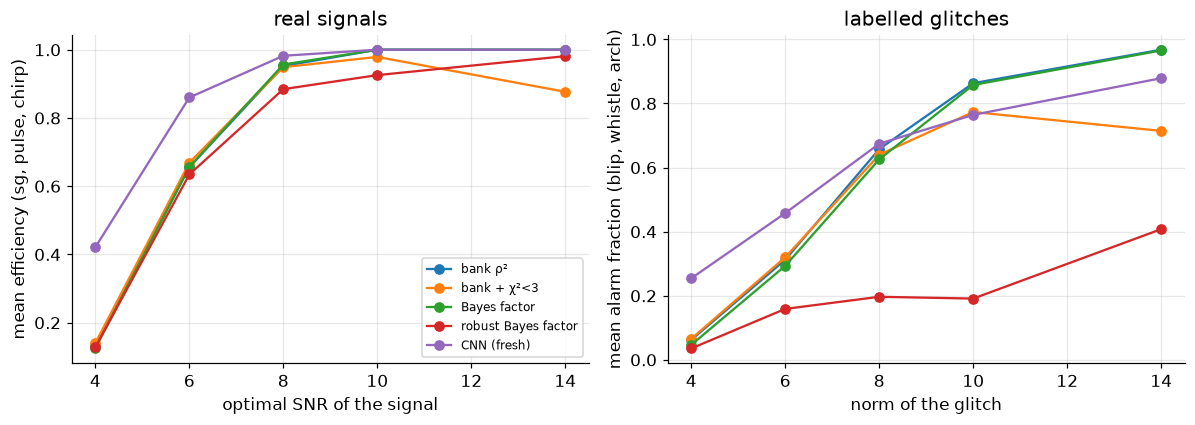

In [5]:
# efficiency of real signals at FAP 1e-2 (price of the robust statistic)
eff = R[R.role == "signal"].groupby("norm")[list(DET)].mean(); print("mean efficiency over sg/pulse/chirp:"); print(eff.round(3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for n in DET: ax[0].plot(SNR, R[R.role == "signal"].groupby("norm")[DET[n] if False else n].mean(), marker="o", label=n)
ax[0].set_xlabel("optimal SNR of the signal"); ax[0].set_ylabel("mean efficiency (sg, pulse, chirp)"); ax[0].legend(fontsize=8); ax[0].set_title("real signals")
for n in DET: ax[1].plot(SNR, R[R.role == "glitch"].groupby("norm")[n].mean(), marker="o", label=n)
ax[1].set_xlabel("norm of the glitch"); ax[1].set_ylabel("mean alarm fraction (blip, whistle, arch)"); ax[1].set_title("labelled glitches")
fig.tight_layout(); g.savefig(fig, "fig21_glitch_discrimination"); plt.show()
g.save_json(dict(observed_FAP_test=nz, B100_test=b100, B100_val=b100v, rates=R.to_dict("records"), auc=AUC.to_dict("records"), eta=ETA), "21_summary.json")

## Output and next step

`results/21_summary.json`, `figures/fig21_glitch_discrimination`, `glitch_tools.py`. Next: regression of the binary parameters (extension 25).